In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

device=cuda torch=2.11.0+cu130 timm=1.0.30
data root: /kaggle/input/datasets/ashenafifasilkebede/dataset
0=Normal 1=OSCC     0     1
split is_aug               
test  False        31    95
train False       231   747
      True       2204  1764
val   False        28    92
cached (5192, 3, 224, 224) in 255s

clean evaluation set (original val+test): 246 images (59 normal, 187 OSCC)
protocol C training set (original-only train): 978 images

=== near-duplicate audit (DINOv2, D4-averaged) ===


config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

  A_random_pooled / all              n_test= 779 median_sim=0.971  >0.9:  96.0%  >0.95:  75.0%  >0.98:  33.4%
  A_random_pooled / originals only   n_test= 160 median_sim=0.971  >0.9:  95.6%  >0.95:  76.2%  >0.98:  35.6%
  B_official_train / all             n_test= 246 median_sim=0.953  >0.9:  93.1%  >0.95:  56.5%  >0.98:   8.1%
  C_originals_only_train / all       n_test= 246 median_sim=0.953  >0.9:  92.7%  >0.95:  56.1%  >0.98:   8.1%

=== seed 42 | A_random_pooled | EfficientNet-B3 | train=4413 test=779 ===


... (8 outputs left out)

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

    epoch 1/6  train_loss=0.4413
    epoch 2/6  train_loss=0.1112
    epoch 3/6  train_loss=0.0430
    epoch 4/6  train_loss=0.0242
    epoch 5/6  train_loss=0.0199
    epoch 6/6  train_loss=0.0168
    {'acc': 92.28, 'prec': 93.75, 'sens': 96.26, 'spec': 79.66, 'f1': 94.99, 'auc': 97.1, 'ece': 5.28} CI95=[89.0,95.1]

=== seed 42 | C_originals_only_train | EfficientNet-B3 | train=978 test=246 ===
    epoch 1/8  train_loss=1.5991
    epoch 2/8  train_loss=0.5934
    epoch 3/8  train_loss=0.3571
    epoch 4/8  train_loss=0.2442
    epoch 5/8  train_loss=0.1985
    epoch 6/8  train_loss=0.1673
    epoch 7/8  train_loss=0.1263
    epoch 8/8  train_loss=0.1087
    {'acc': 87.8, 'prec': 89.45, 'sens': 95.19, 'spec': 64.41, 'f1': 92.23, 'auc': 91.13, 'ece': 8.99} CI95=[83.7,91.5]

=== seed 42 | C_originals_only_train | Phikon (full FT) | train=978 test=246 ===


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

    epoch 1/6  train_loss=0.6439
    epoch 2/6  train_loss=0.2868
    epoch 3/6  train_loss=0.1954
    epoch 4/6  train_loss=0.1447
    epoch 5/6  train_loss=0.1214
    epoch 6/6  train_loss=0.1166
    {'acc': 92.28, 'prec': 93.75, 'sens': 96.26, 'spec': 79.66, 'f1': 94.99, 'auc': 96.11, 'ece': 5.19} CI95=[88.6,95.5]

           model               protocol  n_train  n_test   acc  acc_std  ci_lo  ci_hi  prec  sens  spec    f1   auc  ece  acc_on_originals  acc_on_augmented
 EfficientNet-B3        A_random_pooled     4413     779 97.43      NaN  96.27  98.46 98.49 96.54 98.40 97.51 99.72 1.23             95.62             97.90
 EfficientNet-B3       B_official_train     4946     246 88.62      NaN  84.96  92.28 91.62 93.58 72.88 92.59 94.03 7.48             88.62               NaN
 EfficientNet-B3 C_originals_only_train      978     246 87.80      NaN  83.74  91.46 89.45 95.19 64.41 92.23 91.13 8.99             87.80               NaN
Phikon (full FT)        A_random_pooled     4413    

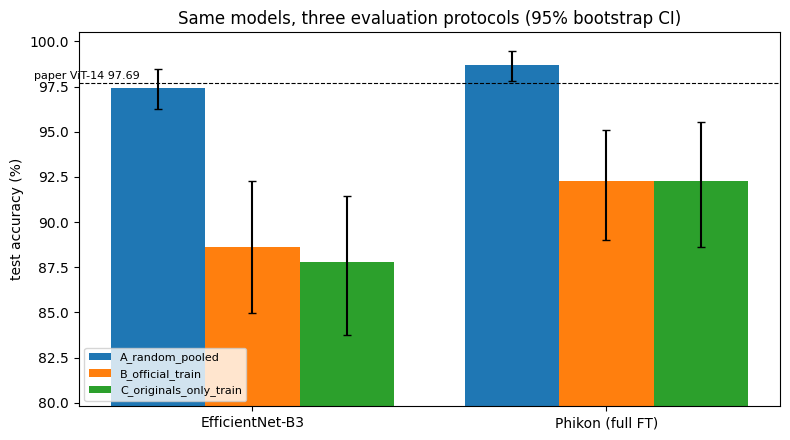


Saved protocol_runs.csv, protocol_summary.csv, near_duplicate_audit.csv, protocol_comparison.png, protocol_results.json -> /kaggle/working
NOTE: clean test set has 246 images; 1 error = 0.41 pts. Use the CI columns, and use SEEDS=[42,43,44] for protocol A.


In [1]:
# =====================================================================
#  OSCC histopathology: "literature protocol" vs "clean-originals protocol"  (v3)
#  Single-file Kaggle script (paste into one notebook cell, or run as .py)
#
#  Question answered: how much of the 97-99% accuracy reported on this
#  dataset comes from the evaluation protocol rather than the model?
#
#  Same two models (EfficientNet-B3, Phikon full fine-tune) are trained under:
#    A  random stratified split of ALL 5192 images (85/15 -> 779-image test,
#       the evaluation size implied by Islam et al., arXiv 2411.14184)
#    B  official Kaggle train folder  -> tested on ORIGINAL val+test images only
#    C  ORIGINAL-only train images    -> same clean test as B
#       (tests the "augmentation shortcut": clean-looking => OSCC)
#  Extras: aug-vs-original breakdown inside protocol A, near-duplicate audit
#  (test->train similarity) per protocol, grouped bar chart.
#
#  Kaggle: Accelerator = GPU, Internet = ON.  ~40-60 min on a T4 with 1 seed.
#  No model selection on test data: every model is evaluated at its LAST epoch.
# =====================================================================

# %% ------------------------------ 0. SETUP ---------------------------
import os, sys, json, math, time, random, warnings, subprocess
warnings.filterwarnings("ignore")

def _pip(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)
for _mod, _pkg in [("timm", "timm"), ("transformers", "transformers"),
                   ("sklearn", "scikit-learn")]:
    try: __import__(_mod)
    except ImportError: _pip(_pkg)

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import roc_auc_score, confusion_matrix
from sklearn.model_selection import train_test_split
import timm

CFG = dict(
    DATA_ROOT=None,                       # None = auto-find under /kaggle/input
    IMG=224, NUM_WORKERS=2, FT_BS=32,
    SEEDS=[42],                           # e.g. [42, 43, 44] for mean±std (3x time)
    TEST_FRAC_A=0.15,                     # protocol A test fraction (779 images)
    # (label, key, learning rate, epochs)
    RUNS=[("EfficientNet-B3", "effb3", 3e-4, 8),
          ("Phikon (full FT)", "phikon", 1.5e-5, 6)],
    PROTOCOLS=["A_random_pooled", "B_official_train", "C_originals_only_train"],
    AUDIT=True,                           # DINOv2 near-duplicate audit (~3-4 min)
    OUT="/kaggle/working",
)
# Reported numbers on this dataset, for the final comparison printout
LIT = {"Islam et al. 2024, EfficientNetB3 (arXiv 2411.14184)": 98.33,
       "Your paper, ViT-14 (Table 21)": 97.69,
       "Ahmad et al. 2023, SVM + deep features": 97.00}

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
AMP = DEVICE == "cuda"
os.makedirs(CFG["OUT"], exist_ok=True)
print(f"device={DEVICE} torch={torch.__version__} timm={timm.__version__}")

# %% ------------------------- 1. DATA ---------------------------------
def find_root():
    if CFG["DATA_ROOT"]: return CFG["DATA_ROOT"]
    for dp, dn, _ in os.walk("/kaggle/input"):
        if {"train", "val", "test"} <= {d.lower() for d in dn}: return dp
    raise FileNotFoundError("train/val/test folders not found under /kaggle/input")

ROOT = find_root(); print("data root:", ROOT)
EXT = (".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp")
PATHS, LAB, SPL = [], [], []
for sp in os.listdir(ROOT):
    if sp.lower() not in ("train", "val", "test"): continue
    for cls in os.listdir(os.path.join(ROOT, sp)):
        lab = {"normal": 0, "oscc": 1}.get(cls.lower())
        if lab is None: continue
        for f in sorted(os.listdir(os.path.join(ROOT, sp, cls))):
            if f.lower().endswith(EXT):
                PATHS.append(os.path.join(ROOT, sp, cls, f)); LAB.append(lab); SPL.append(sp.lower())
Y, SPLIT, N = np.array(LAB), np.array(SPL), len(PATHS)
IS_AUG = np.array([os.path.basename(p).lower().startswith("aug") for p in PATHS])
TR, VA, TE = (np.where(SPLIT == s)[0] for s in ("train", "val", "test"))
print(pd.crosstab([SPLIT, IS_AUG], Y, rownames=["split", "is_aug"], colnames=["0=Normal 1=OSCC"]))
if IS_AUG.sum() == 0:
    print("WARNING: no files starting with 'aug' found; protocol C == protocol B and the "
          "aug/original breakdown is meaningless. Check filenames.")

class ImgDS(torch.utils.data.Dataset):
    def __len__(self): return N
    def __getitem__(self, i):
        im = Image.open(PATHS[i])
        try: im.draft("RGB", (CFG["IMG"] * 2, CFG["IMG"] * 2))
        except Exception: pass
        im = im.convert("RGB").resize((CFG["IMG"],) * 2, Image.BICUBIC)
        return torch.from_numpy(np.asarray(im).copy()).permute(2, 0, 1)

t0 = time.time()
X224 = torch.empty((N, 3, CFG["IMG"], CFG["IMG"]), dtype=torch.uint8); _i = 0
for b in torch.utils.data.DataLoader(ImgDS(), batch_size=64, num_workers=CFG["NUM_WORKERS"]):
    X224[_i:_i + len(b)] = b; _i += len(b)
print(f"cached {tuple(X224.shape)} in {time.time()-t0:.0f}s")

# %% ------------------------- 2. METRICS ------------------------------
def ece_score(p, y, bins=15):
    conf, pred = p.max(1), p.argmax(1); hit = (pred == y).astype(float); e = 0.0
    edges = np.linspace(0, 1, bins + 1)
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.mean() * abs(hit[m].mean() - conf[m].mean())
    return e * 100

def clf_metrics(y, p):
    pred = p.argmax(1)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    acc = (tp + tn) / len(y); prec = tp / max(tp + fp, 1)
    sens = tp / max(tp + fn, 1); spec = tn / max(tn + fp, 1)
    f1 = 2 * prec * sens / max(prec + sens, 1e-9)
    auc = roc_auc_score(y, p[:, 1]) if len(np.unique(y)) > 1 else float("nan")
    return dict(acc=acc * 100, prec=prec * 100, sens=sens * 100, spec=spec * 100,
                f1=f1 * 100, auc=auc * 100, ece=ece_score(p, y))

def boot_ci(y, pred, n=1000, seed=0):
    rng = np.random.default_rng(seed); a = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y)); a.append((y[i] == pred[i]).mean())
    return np.percentile(a, [2.5, 97.5]) * 100

# %% ------------------- 3. MODELS + TRAINING --------------------------
IMN = ((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))

class HFBackbone(nn.Module):
    def __init__(self, repo):
        super().__init__()
        from transformers import AutoModel
        self.b = AutoModel.from_pretrained(repo)
        self.head = nn.Linear(self.b.config.hidden_size, 2)
    def forward(self, x):
        return self.head(self.b(pixel_values=x).last_hidden_state[:, 0])

def build_model(key):
    if key == "effb3":
        return timm.create_model("efficientnet_b3", pretrained=True, num_classes=2)
    if key == "phikon":
        return HFBackbone("owkin/phikon")
    raise ValueError(key)

def train_eval(key, lr, epochs, tr_idx, eval_sets, seed):
    """Train on tr_idx for a fixed number of epochs (NO checkpoint selection),
    return {name: softmax probs} for each index set in eval_sets."""
    seed_all(seed)
    m = build_model(key).to(DEVICE)
    mean = torch.tensor(IMN[0], device=DEVICE).view(1, 3, 1, 1)
    std = torch.tensor(IMN[1], device=DEVICE).view(1, 3, 1, 1)
    prep = lambda xb: (xb.to(DEVICE).float() / 255 - mean) / std
    bs = CFG["FT_BS"]
    is_head = lambda n: n.startswith(("head", "classifier"))
    head = [p for n, p in m.named_parameters() if is_head(n)]
    body = [p for n, p in m.named_parameters() if not is_head(n)]
    opt = torch.optim.AdamW([dict(params=body, lr=lr), dict(params=head, lr=lr * 10)],
                            weight_decay=0.05)
    steps = epochs * math.ceil(len(tr_idx) / bs)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[lr, lr * 10],
                                                total_steps=steps, pct_start=0.15)
    scaler = torch.amp.GradScaler("cuda", enabled=AMP)

    @torch.no_grad()
    def predict(idx):
        m.eval(); o = []
        for i in range(0, len(idx), 64):
            with torch.autocast("cuda", dtype=torch.float16, enabled=AMP):
                o.append(m(prep(X224[idx[i:i + 64]])).float().softmax(1).cpu())
        return torch.cat(o).numpy()

    for ep in range(epochs):
        m.train(); perm = np.random.permutation(tr_idx); tot, nb = 0.0, 0
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            if len(idx) < 2: continue                      # BatchNorm needs >=2
            xb = X224[torch.as_tensor(idx)]
            yb = torch.from_numpy(Y[idx]).to(DEVICE)
            fl = torch.rand(len(idx)) < .5
            xb = torch.where(fl.view(-1, 1, 1, 1), xb.flip(3), xb)
            fl = torch.rand(len(idx)) < .5
            xb = torch.where(fl.view(-1, 1, 1, 1), xb.flip(2), xb)
            xb = torch.rot90(xb, random.randint(0, 3), (2, 3))
            with torch.autocast("cuda", dtype=torch.float16, enabled=AMP):
                loss = F.cross_entropy(m(prep(xb)).float(), yb)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item(); nb += 1
        print(f"    epoch {ep+1}/{epochs}  train_loss={tot/max(nb,1):.4f}")
    out = {name: predict(idx) for name, idx in eval_sets.items()}
    del m, opt; torch.cuda.empty_cache()
    return out

# %% ------------------- 4. NEAR-DUPLICATE AUDIT -----------------------
@torch.no_grad()
def dino_d4_features():
    from transformers import AutoModel
    m = AutoModel.from_pretrained("facebook/dinov2-base").to(DEVICE).eval()
    mean = torch.tensor(IMN[0], device=DEVICE).view(1, 3, 1, 1)
    std = torch.tensor(IMN[1], device=DEVICE).view(1, 3, 1, 1)
    out = []
    for i in range(0, N, 64):
        xb = (X224[i:i + 64].to(DEVICE).float() / 255 - mean) / std; fs = []
        with torch.autocast("cuda", dtype=torch.float16, enabled=AMP):
            for fl in (False, True):
                xf = xb.flip(3) if fl else xb
                for r in range(4):
                    h = m(pixel_values=torch.rot90(xf, r, (2, 3))).last_hidden_state
                    fs.append(torch.cat([h[:, 0], h[:, 1:].mean(1)], 1).float())
        out.append(torch.stack(fs).mean(0).cpu())
    del m; torch.cuda.empty_cache()
    f = torch.cat(out).numpy()
    return f / np.linalg.norm(f, axis=1, keepdims=True)

def audit(Fn, tr, te, label):
    mx = (Fn[te] @ Fn[tr].T).max(1)
    msg = (f"  {label:34s} n_test={len(te):4d} median_sim={np.median(mx):.3f}  "
           + "  ".join(f">{t}: {(mx > t).mean()*100:5.1f}%" for t in (.90, .95, .98)))
    print(msg)
    return dict(label=label, n_test=len(te), median_sim=float(np.median(mx)),
                frac_gt95=float((mx > .95).mean() * 100), frac_gt98=float((mx > .98).mean() * 100))

# %% ------------------- 5. RUN ALL PROTOCOLS --------------------------
B_EVAL = np.where(np.isin(SPLIT, ["val", "test"]) & ~IS_AUG)[0]   # clean original images
print(f"\nclean evaluation set (original val+test): {len(B_EVAL)} images "
      f"({int((Y[B_EVAL]==0).sum())} normal, {int((Y[B_EVAL]==1).sum())} OSCC)")
C_TRAIN = TR[~IS_AUG[TR]]
print(f"protocol C training set (original-only train): {len(C_TRAIN)} images")

def make_splits(seed):
    tr_a, te_a = train_test_split(np.arange(N), test_size=CFG["TEST_FRAC_A"],
                                  stratify=Y, random_state=seed)
    return {"A_random_pooled": (tr_a, te_a),
            "B_official_train": (TR, B_EVAL),
            "C_originals_only_train": (C_TRAIN, B_EVAL)}

AUDIT_ROWS, ROWS = [], []
if CFG["AUDIT"]:
    print("\n=== near-duplicate audit (DINOv2, D4-averaged) ===")
    try:
        Fn = dino_d4_features()
        for proto, (tr, te) in make_splits(CFG["SEEDS"][0]).items():
            if proto not in CFG["PROTOCOLS"]: continue
            AUDIT_ROWS.append(dict(protocol=proto, subset="all", **audit(Fn, tr, te, f"{proto} / all")))
            if proto.startswith("A"):
                o = te[~IS_AUG[te]]
                if len(o): AUDIT_ROWS.append(dict(protocol=proto, subset="originals_only",
                                                  **audit(Fn, tr, o, f"{proto} / originals only")))
        pd.DataFrame(AUDIT_ROWS).to_csv(f"{CFG['OUT']}/near_duplicate_audit.csv", index=False)
    except Exception as e:
        print(f"  audit failed: {type(e).__name__}: {str(e)[:150]}")

for seed in CFG["SEEDS"]:
    splits = make_splits(seed)
    for proto in CFG["PROTOCOLS"]:
        tr, te = splits[proto]
        for label, key, lr, epochs in CFG["RUNS"]:
            print(f"\n=== seed {seed} | {proto} | {label} | train={len(tr)} test={len(te)} ===")
            try:
                p = train_eval(key, lr, epochs, tr, {"test": te}, seed)["test"]
                m = clf_metrics(Y[te], p)
                lo, hi = boot_ci(Y[te], p.argmax(1))
                row = dict(protocol=proto, model=label, seed=seed, n_train=len(tr),
                           n_test=len(te), **m, ci_lo=lo, ci_hi=hi)
                correct = (p.argmax(1) == Y[te])
                row["acc_on_originals"] = correct[~IS_AUG[te]].mean() * 100 if (~IS_AUG[te]).any() else np.nan
                row["acc_on_augmented"] = correct[IS_AUG[te]].mean() * 100 if IS_AUG[te].any() else np.nan
                ROWS.append(row)
                print("   ", {k: round(float(v), 2) for k, v in m.items()},
                      f"CI95=[{lo:.1f},{hi:.1f}]")
                if IS_AUG[te].any():
                    print(f"    acc on originals={row['acc_on_originals']:.2f} "
                          f"(n={(~IS_AUG[te]).sum()}) | on augmented={row['acc_on_augmented']:.2f} "
                          f"(n={IS_AUG[te].sum()})")
            except Exception as e:
                print(f"   FAILED: {type(e).__name__}: {str(e)[:200]}")
            torch.cuda.empty_cache()

# %% ------------------- 6. SUMMARY ------------------------------------
df = pd.DataFrame(ROWS)
df.to_csv(f"{CFG['OUT']}/protocol_runs.csv", index=False)
if len(df):
    agg = (df.groupby(["model", "protocol"])
             .agg(n_train=("n_train", "first"), n_test=("n_test", "first"),
                  acc=("acc", "mean"), acc_std=("acc", "std"),
                  ci_lo=("ci_lo", "first"), ci_hi=("ci_hi", "first"),
                  prec=("prec", "mean"), sens=("sens", "mean"), spec=("spec", "mean"),
                  f1=("f1", "mean"), auc=("auc", "mean"), ece=("ece", "mean"),
                  acc_on_originals=("acc_on_originals", "mean"),
                  acc_on_augmented=("acc_on_augmented", "mean"))
             .reset_index())
    pd.set_option("display.width", 250); pd.set_option("display.max_columns", 50)
    print("\n" + "=" * 110)
    print(agg.round(2).to_string(index=False))
    agg.round(3).to_csv(f"{CFG['OUT']}/protocol_summary.csv", index=False)

    print("\n--- inflation of accuracy caused by the evaluation protocol ---")
    for model in agg.model.unique():
        s = agg[agg.model == model].set_index("protocol").acc
        if {"A_random_pooled", "B_official_train"} <= set(s.index):
            print(f"{model:18s} A (random pooled) {s['A_random_pooled']:.2f}  vs  "
                  f"B (clean originals) {s['B_official_train']:.2f}  "
                  f"-> inflation {s['A_random_pooled']-s['B_official_train']:+.2f} pts")
        if {"B_official_train", "C_originals_only_train"} <= set(s.index):
            print(f"{'':18s} originals-only training (C) {s['C_originals_only_train']:.2f} "
                  f"vs official train (B) {s['B_official_train']:.2f} "
                  f"-> {s['C_originals_only_train']-s['B_official_train']:+.2f} pts "
                  f"(positive = augmented training data was hurting)")
    print("\n--- reported in the literature (protocol differs; verify before citing) ---")
    for k, v in LIT.items(): print(f"  {v:6.2f}  {k}")

    # grouped bar chart
    protos = [p for p in CFG["PROTOCOLS"] if p in set(agg.protocol)]
    models = list(agg.model.unique()); w = 0.8 / max(len(protos), 1)
    plt.figure(figsize=(8, 4.5))
    for j, p in enumerate(protos):
        sub = agg[agg.protocol == p].set_index("model").reindex(models)
        err = np.vstack([sub.acc - sub.ci_lo, sub.ci_hi - sub.acc])
        plt.bar(np.arange(len(models)) + j * w, sub.acc, w, yerr=err, capsize=3, label=p)
    plt.xticks(np.arange(len(models)) + w * (len(protos) - 1) / 2, models)
    plt.ylim(max(50, agg.acc.min() - 8), 100.5); plt.ylabel("test accuracy (%)")
    plt.axhline(97.69, ls="--", c="k", lw=.8); plt.text(-0.35, 97.9, "paper ViT-14 97.69", fontsize=8)
    plt.title("Same models, three evaluation protocols (95% bootstrap CI)")
    plt.legend(fontsize=8, loc="lower left"); plt.tight_layout()
    plt.savefig(f"{CFG['OUT']}/protocol_comparison.png", dpi=150); plt.show()

json.dump(dict(cfg=CFG, audit=AUDIT_ROWS, runs=ROWS), open(f"{CFG['OUT']}/protocol_results.json", "w"),
          indent=2, default=str)
print(f"\nSaved protocol_runs.csv, protocol_summary.csv, near_duplicate_audit.csv, "
      f"protocol_comparison.png, protocol_results.json -> {CFG['OUT']}")
print(f"NOTE: clean test set has {len(B_EVAL)} images; 1 error = {100/max(len(B_EVAL),1):.2f} pts. "
      "Use the CI columns, and use SEEDS=[42,43,44] for protocol A.")